# Native EmoWOZ single-utterance RoBERTa
Workstream 4 extension; original B3 implementation credited. Training uses the official train/dev partitions and native labels.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
import json

import pandas as pd
from IPython.display import Image, display

## Dev selection
Five seeds, three fixed epochs; test does not select checkpoints.

{'best_seed_on_dev': 1,
 'metric': 'weighted_f1_no_neutral',
 'test_used_for_selection': False}

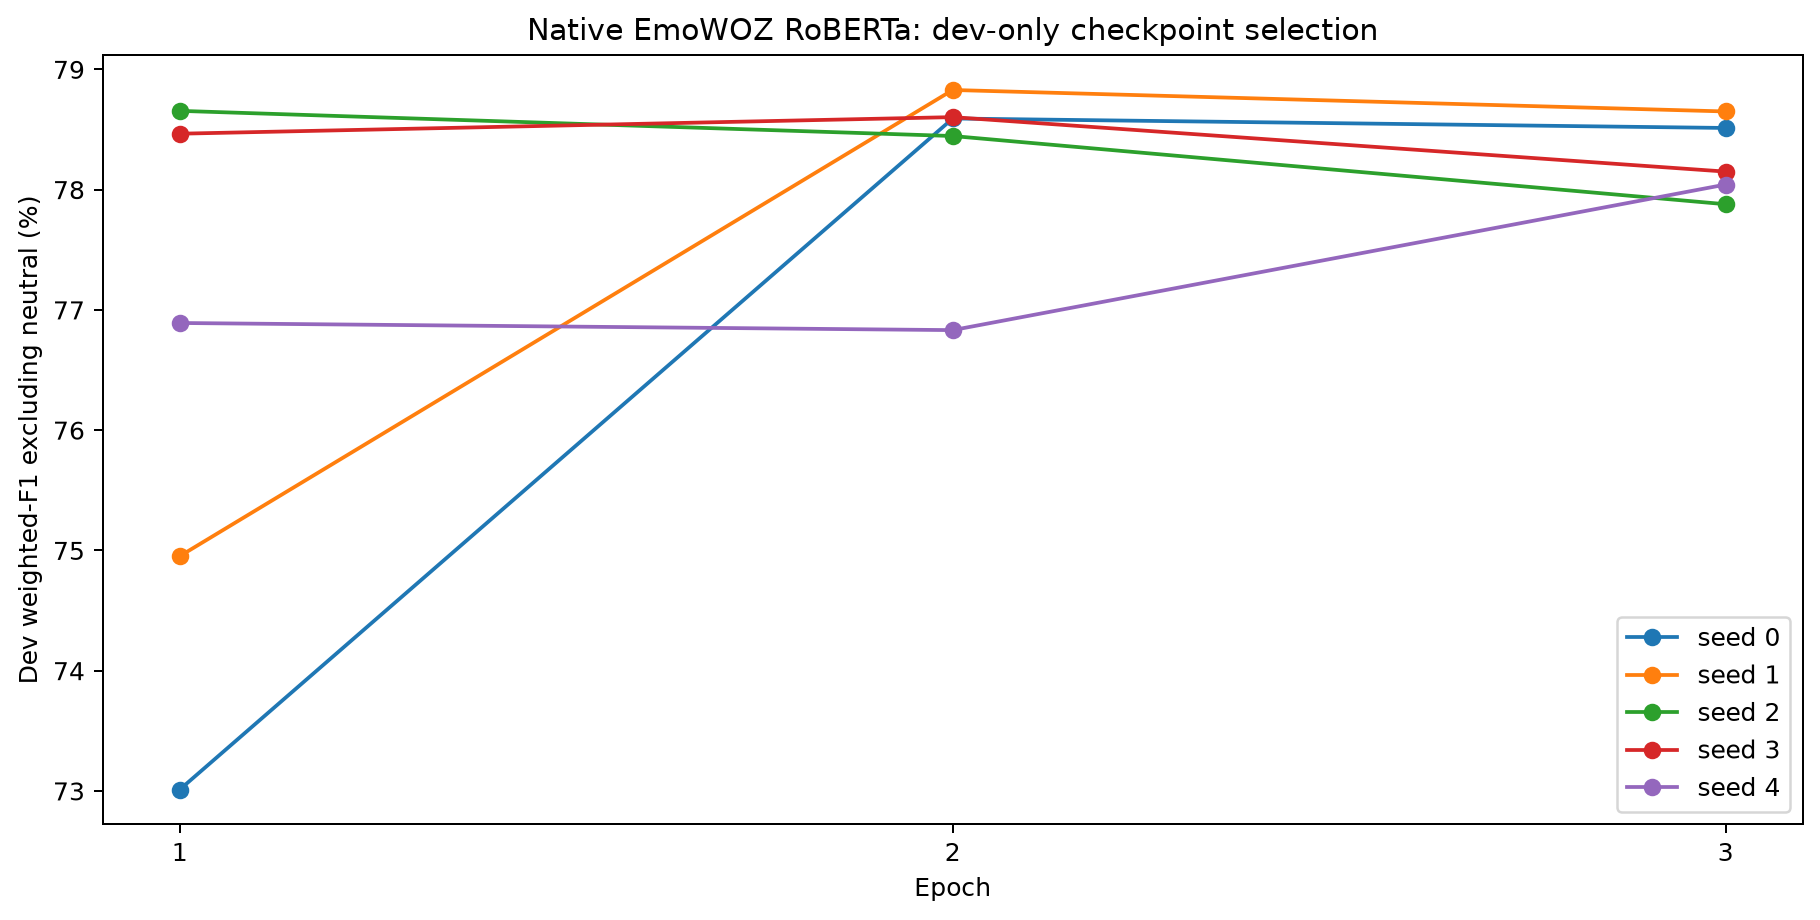

In [2]:
display(json.loads(Path("reports/b3/emowoz/selection.json").read_text()))
display(Image(filename="reports/b3/emowoz/figures/learning_curves.png"))

## Test comparison
Same native labels and targets for all four utterance-only baselines.

,model,n,headline,std,ci_low,ci_high,macro_f1_no_neutral,macro_f1,derived_shift_f1
0,b1,8634,0.764975,0.000000,0.745574,0.782777,0.471027,0.533918,0.743627
1,b2_bigru,8634,0.770529,0.004528,0.748536,0.781185,0.482423,0.542609,0.739284
2,b2_bilstm,8634,0.770060,0.001909,0.748894,0.785174,0.487349,0.547008,0.741249
3,b3_roberta,8634,0.780853,0.002877,0.760494,0.800820,0.500039,0.560973,0.769253


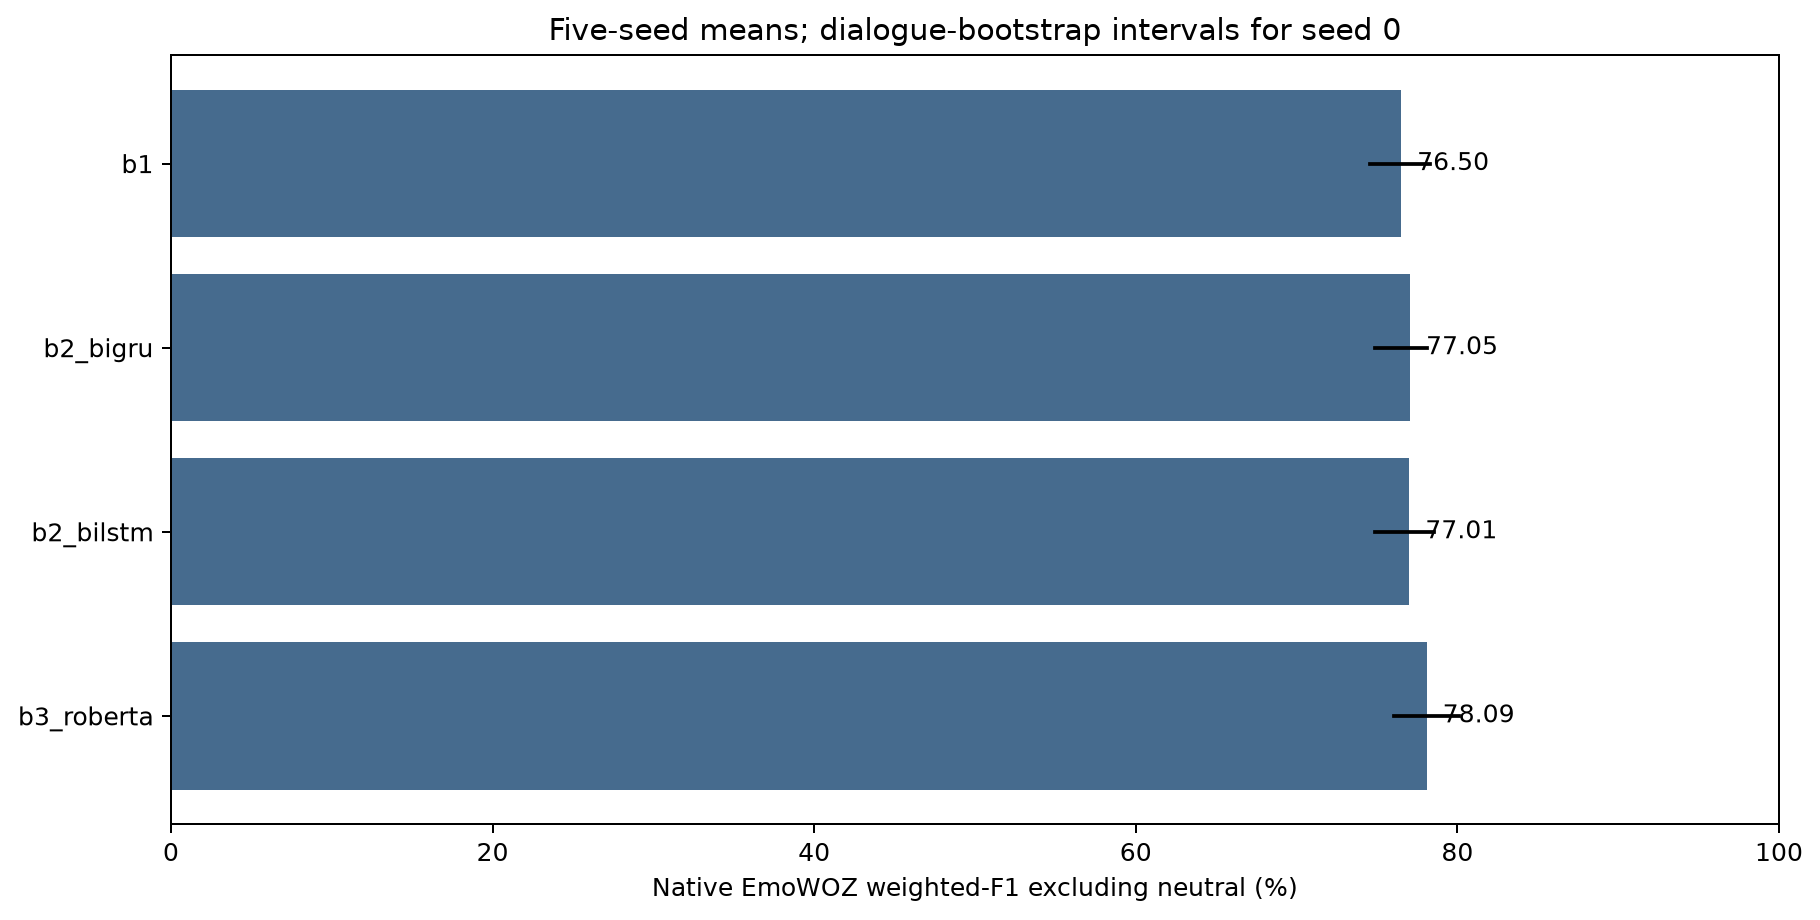

In [3]:
display(pd.read_csv("reports/b3/emowoz/comparison_b1_b2_b3.csv"))
display(Image(filename="reports/b3/emowoz/figures/headline_comparison.png"))

## First / stable / shift
Gold strata are evaluation metadata, not inputs. Different class mixtures mean a higher shift-subset F1 does not establish dialogue understanding.

,model,group,weighted_f1_no_neutral
0,b1,stratum:first,0.489712
1,b1,stratum:stable,0.673813
2,b1,stratum:shift,0.819310
3,b2_bigru,stratum:first,0.448338
4,b2_bigru,stratum:stable,0.687220
5,b2_bigru,stratum:shift,0.828274
6,b2_bilstm,stratum:first,0.445490
7,b2_bilstm,stratum:stable,0.681308
8,b2_bilstm,stratum:shift,0.830054
9,b3_roberta,stratum:first,0.577534


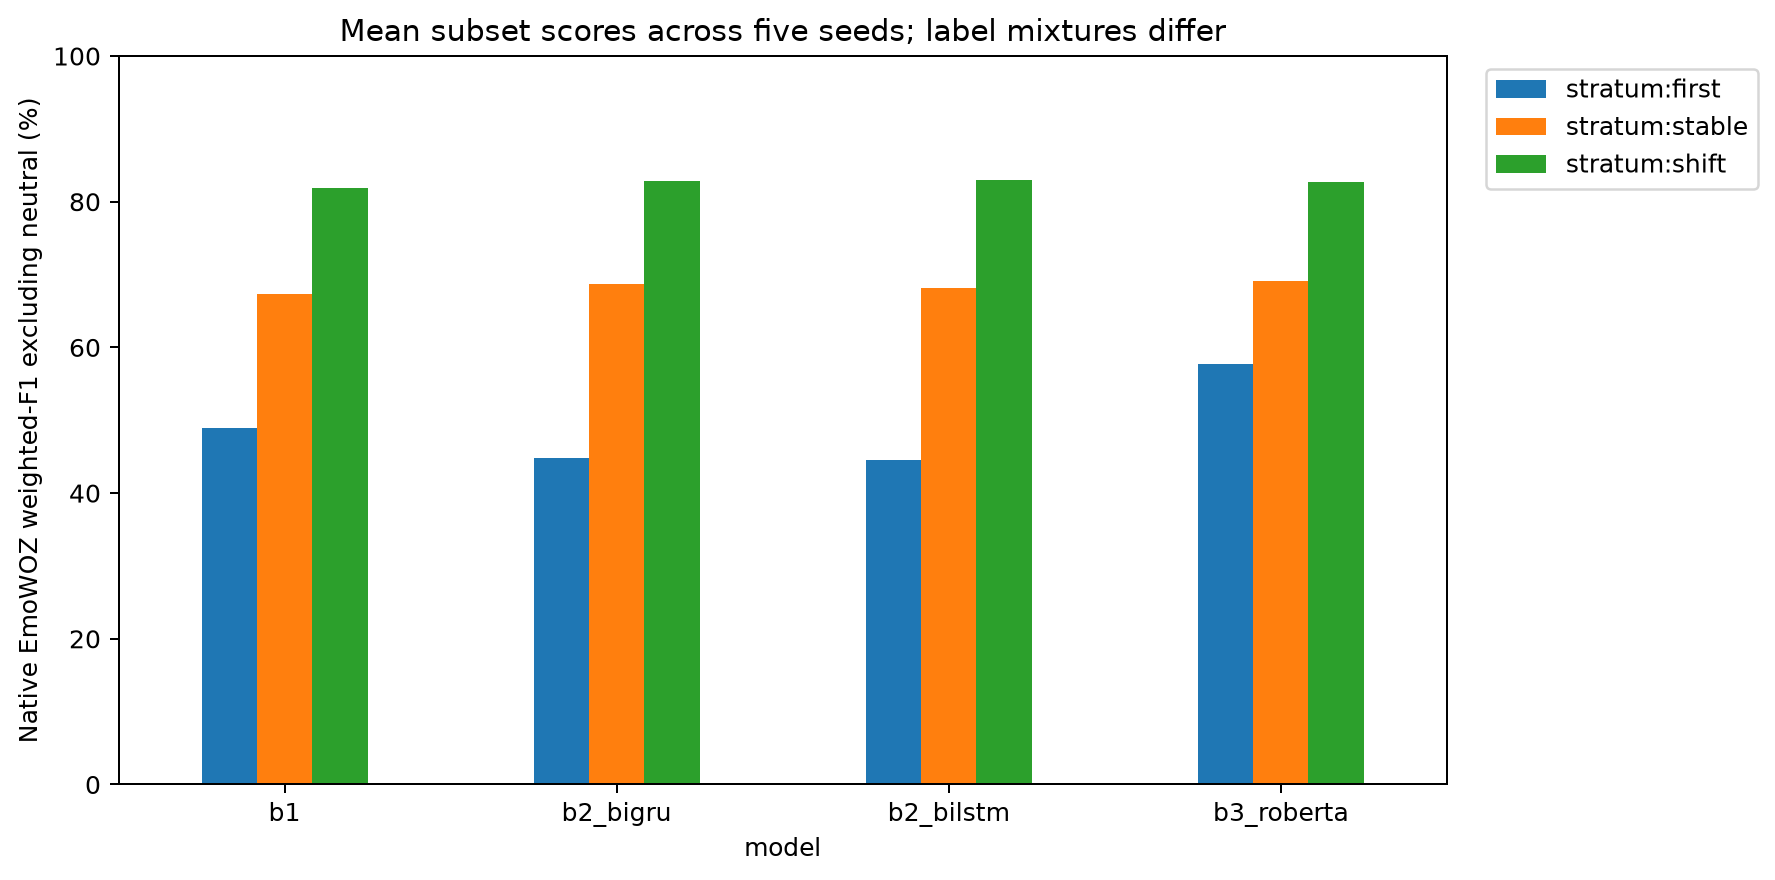

In [4]:
display(pd.read_csv("reports/b3/emowoz/figures/strata.csv"))
display(Image(filename="reports/b3/emowoz/figures/strata.png"))

## Native-label demo
Large weights are shared separately. System turns are not neutral targets.

In [5]:
from emotionshift.models.roberta import RobertaUtterance

selection = json.loads(Path("reports/b3/emowoz/selection.json").read_text())
seed = selection["best_seed_on_dev"]
model = RobertaUtterance.load(f"models/b3_emowoz/seed{seed}", device="cpu")
print(model.labels)
print(model.predict(["Thank you, that was helpful.", "You did not answer my question."]))

C:\Users\Lenovo\Documents\Codex\2026-10-30\referenced-chatgpt-conversation-this-is-an\work\emowoz-cuda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   6%|▋         | 13/201 [00:00<00:01, 104.65it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1142.01it/s]

['neutral', 'fearful', 'dissatisfied', 'apologetic', 'abusive', 'excited', 'satisfied']
['satisfied', 'dissatisfied']


## Verification and interpretation
Report per-class metrics alongside weighted-F1; label imbalance can mask minority-class errors. These are in-domain experiments, without dialogue history or cross-dataset transfer.

In [6]:
display(json.loads(Path("reports/b3/emowoz/verification.json").read_text()))

{'prediction_csvs': 5,
 'targets_per_csv': 8634,
 'native_labels_verified': True,
 'dev_selection_verified': True,
 'metrics_recomputed': True,
 'checkpoint_round_trip_verified': True,
 'prediction_sha256': {'predictions\\b3_emowoz_test_seed0.csv': '82f34a57f10bf6cbca8d7fdb6c8a5ad318f285025a5e29e674cdfcd155add5f3',
  'predictions\\b3_emowoz_test_seed1.csv': '1f067e30faab465eb829606964d1549a48dc069417704114675f320cb95c254f',
  'predictions\\b3_emowoz_test_seed2.csv': '7f81ab918c3dc28003e282a8c75f96a22f26ea3611ec7868f5eab31fbf7cccbe',
  'predictions\\b3_emowoz_test_seed3.csv': '992ec5b99bc53f47994dda03f8aa84636d1be509464a2036668efe333ad5f797',
  'predictions\\b3_emowoz_test_seed4.csv': 'b1bb6e996835f2a86c6cedceefd3dbe2764ad9d423c3176cf27f4c57f8f961de'},
 'checkpoint_sha256': {'models\\b3_emowoz\\seed0\\model.safetensors': 'bae9c5fdd8feede4e684e68e64d1d7661f5d7d9a71919fc9f53eb0fd51adae24',
  'models\\b3_emowoz\\seed1\\model.safetensors': '0f81a2f03bcf63a486ac4fa20647ffa9293d0123f3462978a3